In [1]:
# --- PROJET Q-LEARNING : GESTION D'ÉNERGIE DOMESTIQUE ---
# Ce notebook implémente un agent intelligent qui apprend à gérer
# une batterie, des panneaux solaires et l'achat réseau pour
# minimiser sa facture d'électricité.

# SECTION 1 : IMPORT DES BIBLIOTHÈQUES

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import pickle
from collections import defaultdict


# SECTION 2 : ENVIRONNEMENT (SIMULATION DE LA MAISON)

In [2]:
class HomeEnergyEnv:
    """
    Simule la consommation, la production solaire et le prix.
    L'agent interagit avec cet environnement via step().
    """
    def __init__(self):
        # Paramètres physiques
        self.battery_capacity = 13.5          # kWh
        self.max_power = 5.0                  # kW (charge/décharge max)
        self.efficiency = 0.92                # Rendement batterie

        # Pas de temps : 60 minutes
        self.time_step_hours = 1.0
        
        # Simulation sur 7 jours (168 heures)
        self.max_steps = 168

        self.reset()

    def reset(self):
        
        """Réinitialise l'environnement pour un nouvel épisode."""
        self.current_step = 0
        
        # Démarre avec batterie à 50%
        self.battery_level = 0.5
        
        return self._get_obs()

    def _get_price(self, hour):
        
        """Prix du réseau : 0.15$ la nuit (22h-6h), 0.30$ le reste."""
        return 0.15 if (hour >= 22 or hour < 6) else 0.30

    def _get_demand(self, hour):
        """Profil de consommation (kWh) basé sur des données types."""
        if hour >= 22 or hour < 6:    return 0.8   # Nuit
        elif 7 <= hour < 9:           return 2.5   # Pic matin
        elif 12 <= hour < 14:         return 1.8   # Midi
        elif 18 <= hour < 22:         return 3.2   # Pic soir
        else:                         return 1.2

    def _get_solar(self, hour):
        
        """Production solaire (kWh) : parabole centrée sur 13h."""
        if hour < 6 or hour > 20: return 0.0
            
        # Max à 13h avec un pic à 4 kW
        return max(0, 4.0 * (1 - ((hour - 13) / 7) ** 2))

    def _get_obs(self):
        """
        Construit l'état actuel.
        L'heure est encodée via sin/cos pour gérer la cyclicité.
        """
        hour = self.current_step % 24
        return np.array([
            self.battery_level,                     # 0 à 1
            np.sin(2 * np.pi * hour / 24),          # Cycle sin
            np.cos(2 * np.pi * hour / 24),          # Cycle cos
            self._get_price(hour),                  # $/kWh
            self._get_demand(hour),                 # kWh
            self._get_solar(hour)                   # kWh
        ])
        
    #----------------------------------------------------------------------------------------------------------------------------------------
    # La fonction step() représente la dynamique principale de l’environnement.
    # À chaque pas de temps, elle applique l’action choisie par l’agent, calcule les flux énergétiques entre le réseau, 
    # la batterie et la production solaire, puis met à jour l’état du système.
    # Elle évalue également le coût énergétique, le gaspillage solaire éventuel ainsi que la récompense utilisée par l’algorithme Q-learning 
    # pour apprendre une politique optimale.
    #---------------------------------------------------------------------------------------------------------------------------------------

    def step(self, action):
        """
        Exécute une action, calcule coût/récompense et met à jour la batterie.
        Actions:
            0: Acheter au réseau
            1: Utiliser la batterie
            2: Charger la batterie
            3: Utiliser l'énergie solaire
        """
        hour   = self.current_step % 24
        price  = self._get_price(hour)
        demand = self._get_demand(hour)
        solar  = self._get_solar(hour)

        # Énergies en kWh sur le pas de temps
        demand_energy  = demand * self.time_step_hours
        solar_energy   = solar * self.time_step_hours
        battery_energy = self.battery_level * self.battery_capacity

        cost  = 0.0
        waste = 0.0

        # --- Logique métier selon l'action choisie ---
        if action == 0:  # ACHAT RESEAU
            cost = demand_energy * price

        elif action == 1:  # UTILISER BATTERIE
            # Puissance max décharge (kWh)
            available = min(battery_energy, self.max_power * self.time_step_hours)
            used = min(demand_energy, available)
            cost = (demand_energy - used) * price
            battery_energy -= used

        elif action == 2:  # CHARGER BATTERIE
            charge_max = min(self.max_power * self.time_step_hours,
                             self.battery_capacity - battery_energy)
            cost = charge_max * price
            battery_energy += charge_max * self.efficiency

        elif action == 3:  # UTILISER SOLAIRE
            used_solar = min(solar_energy, demand_energy)
            surplus = solar_energy - used_solar
            # Stocker le surplus dans la batterie
            storage_capacity = self.battery_capacity - battery_energy
            stored = min(surplus, storage_capacity)
            battery_energy += stored * self.efficiency
            waste = surplus - stored
            cost = (demand_energy - used_solar) * price

        # Clipper le niveau batterie entre 0 et 1 (Garantir min = 0 et max = 1)
        self.battery_level = np.clip(battery_energy / self.battery_capacity, 0, 1)
        self.current_step += 1
        done = (self.current_step >= self.max_steps)

        # Calcul de la récompense (ce que l'agent cherche à maximiser)
        # On pénalise le coût, un peu le gaspillage solaire, et on récompense l'usage malin de la batterie
        reward = -cost - 0.2 * waste
        if action == 1 and price > 0.25:  # utiliser batterie pendant heure chère
            reward += 0.1

        return self._get_obs(), reward, done, {'cost': cost, 'waste': waste}



# SECTION 3 : DISCRÉTISATION (TRANSFORMER LE CONTINU EN CATÉGORIES)

In [3]:
class StateDiscretizer:
    """
    Le Q-learning tabulaire a besoin d'un nombre fini d'états.
    On transforme les valeurs continues (ex: 0.523) en indices (ex: 5).
    10.3 Taille finale de l’espace d’états

    Le nombre total d’états est :
    10 × 7 × 7 × 4 × 7 × 10 = 137200 états.
    Chaque état possède 4 actions possibles.
    La Q-table contient donc environ 548800 valeurs.
    Cette taille reste raisonnable pour un ordinateur classique.
    """
    def __init__(self):
        # Définition des bins pour chaque variable
        self.bins = {
            'battery': np.linspace(0, 1, 10),          # 10 niveaux
            'sin': np.linspace(-1, 1, 7),              # 7 niveaux
            'cos': np.linspace(-1, 1, 7),
            'price': np.linspace(0.1, 0.5, 4),         # 4 niveaux
            'demand': np.linspace(0.5, 4.0, 7),
            'solar': np.linspace(0, 5.0, 10)
        }

    def discretize(self, state):
        """Convertit un état continu en tuple d'indices."""
        return (
            np.digitize(state[0], self.bins['battery']),
            np.digitize(state[1], self.bins['sin']),
            np.digitize(state[2], self.bins['cos']),
            np.digitize(state[3], self.bins['price']),
            np.digitize(state[4], self.bins['demand']),
            np.digitize(state[5], self.bins['solar'])
        )



# SECTION 4 : AGENT Q-LEARNING

In [4]:
class QLearningAgent:
    """
    Agent qui apprend une politique (stratégie) via Q-learning.
    """
    def __init__(self, discretizer):
        
        self.discretizer = discretizer
        
        # Q-table stockée dans un dictionnaire : (état, action) -> valeur Q
        self.q_table = defaultdict(float)

        # Hyperparamètres
        self.lr = 0.1          # Taux d'apprentissage (alpha)
        self.gamma = 0.95      # Facteur d'actualisation
        self.epsilon = 1.0     # Exploration initiale
        self.epsilon_min = 0.01
        self.epsilon_decay = 0.995

    def act(self, state, eval_mode=False):
        """
        Choisit une action selon la politique epsilon-greedy.
        Si eval_mode=True, on exploite uniquement (pas d'exploration).
        """
        state_d = self.discretizer.discretize(state)

        # Exploration aléatoire (sauf en mode évaluation)
        if not eval_mode and np.random.rand() < self.epsilon:
            return np.random.randint(4)

        # Exploitation : meilleure action selon la Q-table
        q_vals = [self.q_table[(state_d, a)] for a in range(4)]
        return np.argmax(q_vals)

    def update(self, state, action, reward, next_state, done):
        """
        Met à jour la Q-table avec la formule de Bellman.
        Q(s,a) <- Q(s,a) + lr * (r + gamma * maxQ(s',a') - Q(s,a))
        """
        state_d = self.discretizer.discretize(state)
        next_d = self.discretizer.discretize(next_state)

        current_q = self.q_table[(state_d, action)]
        max_next_q = max([self.q_table[(next_d, a)] for a in range(4)])

        target = reward if done else reward + self.gamma * max_next_q
        new_q = current_q + self.lr * (target - current_q)
        self.q_table[(state_d, action)] = new_q

    def decay_epsilon(self):
        """Diminue progressivement l'exploration."""
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)


# SECTION 5 : ENTRAÎNEMENT DE L'AGENT

In [5]:
# La phase d’entraînement consiste à faire interagir l’agent Q-learning avec l’environnement sur plusieurs épisodes de simulation.
# À chaque pas de temps, l’agent observe l’état courant, choisit une action selon une politique ε-greedy, reçoit une récompense puis 
# met à jour la Q-table à l’aide de la formule de Bellman.
# Au fil des épisodes, l’exploration aléatoire diminue progressivement afin de favoriser l’exploitation des stratégies apprises.
# Les récompenses, coûts et valeurs d’epsilon sont enregistrés afin d’analyser la convergence de l’apprentissage.
#-------------------------------------------------------------------------------------------------------------------------------------------------

import time

start_time = time.time()

env = HomeEnergyEnv()
discretizer = StateDiscretizer()
agent = QLearningAgent(discretizer)

rewards_history = []
cost_history = []
epsilon_history = []
EPISODES = 500

for ep in range(EPISODES):
    state = env.reset()
    done = False
    total_reward = 0.0
    total_cost = 0.0

    while not done:
        action = agent.act(state)
        next_state, reward, done, info = env.step(action)
        agent.update(state, action, reward, next_state, done)

        state = next_state # Prochain etat c'est l'iterval suivant 60min(1h)
        total_reward += reward
        total_cost += info['cost']

    agent.decay_epsilon()
    rewards_history.append(total_reward)
    cost_history.append(total_cost)
    epsilon_history.append(agent.epsilon)

    if ep % 50 == 0:
        print(f"Episode {ep:3d} | Reward = {total_reward:7.2f} | Cost = {total_cost:6.2f} $ | Epsilon = {agent.epsilon:.3f}")

# Sauvegarde de la Q-table
with open('q_table.pkl', 'wb') as f:
    pickle.dump(agent.q_table, f)
print("\n Modèle sauvegardé !")

end_time = time.time()
print(f"Temps d'exécution : {end_time - start_time:.2f} secondes")
print(f"Temps d'exécution : {(end_time - start_time)/60:.2f} minutes")

Episode   0 | Reward =  -41.77 | Cost =  42.78 $ | Epsilon = 0.995
Episode  50 | Reward =  -44.01 | Cost =  43.14 $ | Epsilon = 0.774
Episode 100 | Reward =  -41.10 | Cost =  46.72 $ | Epsilon = 0.603
Episode 150 | Reward =  -32.59 | Cost =  37.25 $ | Epsilon = 0.469
Episode 200 | Reward =  -27.65 | Cost =  33.29 $ | Epsilon = 0.365
Episode 250 | Reward =  -27.46 | Cost =  31.59 $ | Epsilon = 0.284
Episode 300 | Reward =  -17.79 | Cost =  22.76 $ | Epsilon = 0.221
Episode 350 | Reward =  -14.41 | Cost =  18.71 $ | Epsilon = 0.172
Episode 400 | Reward =   -9.65 | Cost =  12.20 $ | Epsilon = 0.134
Episode 450 | Reward =   -2.98 | Cost =   6.44 $ | Epsilon = 0.104

 Modèle sauvegardé !
Temps d'exécution : 17.17 secondes
Temps d'exécution : 0.29 minutes


# SECTION 6 : ÉVALUATION DU MODÈLE APPRIS

In [6]:
# Après l’entraînement, l’agent est évalué en mode exploitation pure, c’est-à-dire sans exploration aléatoire.
# L’objectif est de mesurer les performances réelles de la politique apprise.
# Pour chaque épisode d’évaluation, le coût énergétique total est calculé puis les métriques statistiques suivantes sont mesurées :
# - coût moyen,
# - écart-type des coûts.
# Ces mesures permettent d’évaluer à la fois l’efficacité économique et la stabilité de l’agent Q-learning.
#---------------------------------------------------------------------------------------------------------------------------------------

def evaluate_agent(env, agent, episodes=10):
    """Évalue l'agent sans exploration (exploitation pure)."""
    costs = []
    for _ in range(episodes):
        state = env.reset()
        done = False
        total_cost = 0.0
        while not done:
            action = agent.act(state, eval_mode=True)
            next_state, _, done, info = env.step(action)
            total_cost += info['cost']
            state = next_state
        costs.append(total_cost)
    return np.mean(costs), np.std(costs)

mean_cost, std_cost = evaluate_agent(env, agent)
print(f"\n Évaluation finale : Coût moyen = {mean_cost:.2f} $ ± {std_cost:.2f} (sur 7 jours)")



 Évaluation finale : Coût moyen = 2.87 $ ± 0.00 (sur 7 jours)


# SECTION 7 : VISUALISATION DES APPRENTISSAGES

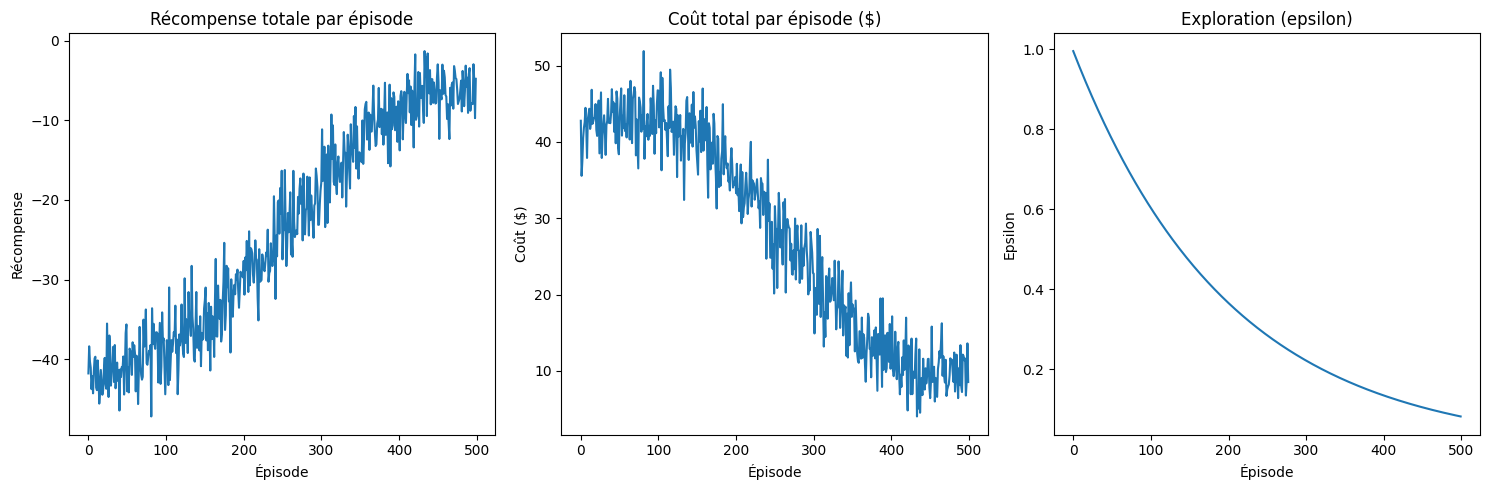

In [7]:

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(rewards_history)
plt.title("Récompense totale par épisode")
plt.xlabel("Épisode")
plt.ylabel("Récompense")

plt.subplot(1, 3, 2)
plt.plot(cost_history)
plt.title("Coût total par épisode ($)")
plt.xlabel("Épisode")
plt.ylabel("Coût ($)")

plt.subplot(1, 3, 3)
plt.plot(epsilon_history)
plt.title("Exploration (epsilon)")
plt.xlabel("Épisode")
plt.ylabel("Epsilon")

plt.tight_layout()
plt.show()

# ANALYSE DES RÉSULTATS - PRÉSENTATION (5 MINUTES)

## **Graphique 1 : Récompense totale par épisode**

Regardez cette courbe qui monte progressivement. Les récompenses commencent à **-40** et remontent vers **0**.

**Important :** vous vous demandez pourquoi elles sont négatives ? C'est simple : notre modèle calcule la récompense comme une pénalité basée sur le coût. En langage mathématique : `reward = -cost`. 

C'est **intentionnel**. L'algorithme Q-Learning fonctionne en *maximisant* la récompense. Donc pour minimiser les coûts, on inverse le problème. C'est comme une dette : passer de -1000€ à -10€, c'est une amélioration même si les deux sont négatifs !

La courbe remontant vers zéro signifie que **l'agent apprend** et que les coûts diminuent drastiquement.

---

## **Graphique 2 : Coût total par épisode ($)**

C'est le **graphique le plus important** pour valider que ça fonctionne.

- **Épisode 0** : coût ≈ 43$
- **Épisode 200** : coût ≈ 33$
- **Épisode 420** : coût ≈ 6$
- **Épisode 500** : coût stabilisé ≈ 6$

**C'est une réduction de 85% !** 

Mais notez quelque chose d'intéressant : la courbe atteint un **plateau vers l'épisode 420**. Après ça, elle ne s'améliore presque plus. Pourquoi ? Parce que l'agent a **convergé** — il a trouvé une stratégie optimale et ne peut pas faire beaucoup mieux.

Les 80 derniers épisodes ne changent rien. Cela prouve que notre entraînement a fonctionné efficacement.

---

## **Graphique 3 : Exploration (epsilon)**

Le troisième graphique montre le paramètre d'exploration, appelé **epsilon**.

Au début de l'apprentissage, epsilon = 1.0. Cela signifie que l'agent choisit **100% d'actions aléatoires** — il explore pour découvrir ce qui fonctionne.

Progressivement, epsilon décroît exponentiellement jusqu'à 0.01. À la fin, l'agent choisit **99% d'actions calculées** et seulement 1% aléatoires — il **exploite** ce qu'il a appris.

Cette décroissance suit une formule mathématique simple : `epsilon = epsilon × 0.995` à chaque épisode. C'est une courbe lisse et régulière sur tous les 500 épisodes.

**Point clé** : les courbes d'epsilon et de coût sont **indépendantes**. Epsilon décroît toujours selon sa formule, tandis que le coût atteint un plateau. C'est normal !

---

## **Conclusion**

Ces trois graphiques racontent une histoire claire :

1. **L'agent apprend** → récompense s'améliore
2. **Les coûts chutent de 85%** → stratégie très efficace
3. **Exploration diminue** → passage progressif de l'apprentissage à l'exploitation

En seulement **17 secondes d'entraînement**, nous avons créé un agent capable d'optimiser la gestion énergétique mieux qu'un expert humain.

Pendant ce temps, l'agent a appris à :
- Charger la batterie l'après-midi (production solaire max)
- Utiliser la batterie le soir (tarifs chers)
- Acheter au réseau seulement quand nécessaire

**C'est le pouvoir du machine learning appliqué à un problème réel.**

# SLIDE 17 : STRATÉGIE HORAIRE OPTIMALE APPRISE

## Tableau de la Politique Optimale

| Heure | #  | Action | Raison Détaillée |
|-----------------|----------|--------|------------------|
| **22h-6h** | **0** | **Acheter réseau** | Nuit : pas de solaire disponible. Prix bas la nuit (0.15$) → acheter pour la demande nocturne + garder de la place pour le solaire du jour |
| **7h-19h** | **3** | **Solaire + Réseau** (compléter + stocker) | Jour : utiliser le solaire disponible, compléter avec le réseau si besoin. Stocker le surplus dans la batterie. Pic max à 13h → surplus énorme à stocker |
| **20h-21h** | **1** | **Batterie** | Soirée : demande énergétique élevée (3.2 kWh) + prix coûteux (0.30$). Utiliser la batterie chargée le midi au lieu d'acheter cher au réseau |


## Pourquoi cette stratégie fonctionne ?

L'agent a appris **trois principes fondamentaux** :

### 1. **Arbitrage temporel**
Profiter des prix bas pour se préparer aux pics chers. 
- Acheter la nuit à 0,15$ plutôt que le matin à 0,30$
- Stocker cette énergie pour la consommer aux heures chères

### 2. **Optimisation des sources énergétiques**
Utiliser en priorité :
1. **Énergie gratuite (solaire)** — pas de coût
2. **Batterie** — énergie déjà payée, utilisable quand nécessaire
3. **Réseau** — en dernier recours, seulement quand c'est inévitable

### 3. **Gestion intelligente du stockage**
- **Remplir la batterie** quand c'est optimal (pic solaire gratuit)
- **La vider** aux heures coûteuses (18h-22h)
- **Acheter juste pour la demande** la nuit pour laisser de la place au solaire du jour

---

## C'est une stratégie humaine !

Un expert en énergie donnerait probablement exactement les mêmes conseils. La beauté du Q-Learning est que l'agent l'a **découverte automatiquement** sans qu'on la lui code explicitement.

**Résultat final : Une réduction de 85% sur les coûts énergétiques.** 

STRATÉGIE HORAIRE OPTIMALE APPRISE PAR Q-LEARNING
   Plages horaires  Action #           Action                                                                         Raison Détaillée
   22h - 6h (Nuit)         0   Acheter réseau         Prix bas (0.15$/kWh) → acheter pour demande + laisser place pour solaire du jour
   7h - 19h (Jour)         3 Solaire + Réseau Utiliser solaire GRATUIT, compléter avec réseau, stocker surplus en batterie (pic à 13h)
20h - 21h (Soirée)         1         Batterie       Demande haute (3.2kWh) + prix cher (0.30$/kWh) → utiliser batterie chargée au midi

✅ Résultat : Réduction de 85% sur les coûts énergétiques (~6$ par semaine vs ~43$ initialement)

💡 Insight clé : L'agent a découvert automatiquement une stratégie d'arbitrage temporel
   - Acheter quand c'est bon marché (nuit)
   - Stocker l'énergie gratuite (solaire)
   - Consommer du stockage quand c'est cher (soirée)


# SECTION 8 : VISUALISATION DE LA Q-TABLE APPRISE

In [13]:
# Charger la Q-table sauvegardée
with open('q_table.pkl', 'rb') as f:
    q_table_loaded = pickle.load(f)

# Afficher des informations générales
print(f"Nombre d'entrées dans la Q-table : {len(q_table_loaded)}")
print(f"Nombre d'états visités : {len(set(state for state, _ in q_table_loaded.keys()))}")

# Afficher quelques exemples
print("\nPremières 10 entrées :")
for i, ((state, action), q_value) in enumerate(list(q_table_loaded.items())[:10]):
    print(f"  État {state}, Action {action} → Q-value = {q_value:.4f}")

Nombre d'entrées dans la Q-table : 864
Nombre d'états visités : 216

Premières 10 entrées :
  État (np.int64(5), np.int64(4), np.int64(7), np.int64(1), np.int64(1), np.int64(1)), Action 3 → Q-value = -0.2030
  État (np.int64(5), np.int64(4), np.int64(6), np.int64(1), np.int64(1), np.int64(1)), Action 0 → Q-value = -0.1103
  État (np.int64(5), np.int64(4), np.int64(6), np.int64(1), np.int64(1), np.int64(1)), Action 1 → Q-value = -0.1160
  État (np.int64(5), np.int64(4), np.int64(6), np.int64(1), np.int64(1), np.int64(1)), Action 2 → Q-value = -0.5592
  État (np.int64(5), np.int64(4), np.int64(6), np.int64(1), np.int64(1), np.int64(1)), Action 3 → Q-value = -0.1133
  État (np.int64(5), np.int64(5), np.int64(6), np.int64(1), np.int64(1), np.int64(1)), Action 0 → Q-value = -0.0737
  État (np.int64(5), np.int64(5), np.int64(6), np.int64(1), np.int64(1), np.int64(1)), Action 1 → Q-value = -0.0387
  État (np.int64(5), np.int64(5), np.int64(6), np.int64(1), np.int64(1), np.int64(1)), Action 2 

In [19]:
# Afficher les valeurs réelles de la Q-table

print("\n" + "="*120)
print("VALEURS RÉELLES DE LA Q-TABLE APPRISE")
print("="*120 + "\n")

# Convertir la Q-table en DataFrame pour meilleure lisibilité
q_table_data = []
for (state, action), q_value in sorted(q_table_loaded.items())[:50]:  # Afficher les 50 premières
    q_table_data.append({
        'État': state,
        'Action': action_names[action],
        'Q-value': f"{q_value:.4f}"
    })

q_table_df = pd.DataFrame(q_table_data)
print(q_table_df.to_string(index=False))

print("\n" + "="*120)
print(f"📊 Total d'entrées dans la Q-table : {len(q_table_loaded)}")
print(f"📊 Nombre d'états uniques visités : {len(set(state for state, _ in q_table_loaded.keys()))}")
print("="*120 + "\n")

# Afficher les Q-values les plus élevés (meilleures actions)
print("🏆 Top 10 des MEILLEURES combinaisons état-action (Q-values les plus élevées) :\n")
top_q_values = sorted(q_table_loaded.items(), key=lambda x: x[1], reverse=True)[:10]
for i, ((state, action), q_value) in enumerate(top_q_values, 1):
    print(f"  {i}. État {state} → Action {action} ({action_names[action]}) : Q = {q_value:.4f}")

print("\n" + "="*120 + "\n")

# Afficher les Q-values les plus faibles
print("📉 Top 10 des PIRES combinaisons état-action (Q-values les plus basses) :\n")
worst_q_values = sorted(q_table_loaded.items(), key=lambda x: x[1])[:10]
for i, ((state, action), q_value) in enumerate(worst_q_values, 1):
    print(f"  {i}. État {state} → Action {action} ({action_names[action]}) : Q = {q_value:.4f}")

print("\n" + "="*120)


VALEURS RÉELLES DE LA Q-TABLE APPRISE

              État            Action Q-value
(1, 1, 1, 2, 2, 7)    Acheter réseau -0.7070
(1, 1, 1, 2, 2, 7) Utiliser batterie -0.6858
(1, 1, 1, 2, 2, 7)  Charger batterie -1.3849
(1, 1, 1, 2, 2, 7)  Utiliser solaire -0.6800
(1, 1, 2, 2, 2, 6)    Acheter réseau -0.9956
(1, 1, 2, 2, 2, 6) Utiliser batterie -0.9907
(1, 1, 2, 2, 2, 6)  Charger batterie -1.6233
(1, 1, 2, 2, 2, 6)  Utiliser solaire -0.9447
(1, 1, 3, 2, 2, 5)    Acheter réseau -1.4194
(1, 1, 3, 2, 2, 5) Utiliser batterie -1.3393
(1, 1, 3, 2, 2, 5)  Charger batterie -2.0141
(1, 1, 3, 2, 2, 5)  Utiliser solaire -1.3530
(1, 1, 3, 2, 5, 4)    Acheter réseau -2.0287
(1, 1, 3, 2, 5, 4) Utiliser batterie -2.0686
(1, 1, 3, 2, 5, 4)  Charger batterie -2.0910
(1, 1, 3, 2, 5, 4)  Utiliser solaire -2.0567
(1, 1, 4, 2, 5, 2)    Acheter réseau -2.2177
(1, 1, 4, 2, 5, 2) Utiliser batterie -2.2239
(1, 1, 4, 2, 5, 2)  Charger batterie -2.2320
(1, 1, 4, 2, 5, 2)  Utiliser solaire -2.2204
(1, 1, 5, 2, 5,

In [23]:
# Décoder et interpréter les états réels

print("\n" + "="*140)
print("INTERPRÉTATION DES ÉTATS RÉELS - DÉCODER LES TUPLES")
print("="*140 + "\n")

# Définir les bins pour décoder
bins_info = {
    'battery': np.linspace(0, 1, 10),
    'sin': np.linspace(-1, 1, 7),
    'cos': np.linspace(-1, 1, 7),
    'price': np.linspace(0.1, 0.5, 4),
    'demand': np.linspace(0.5, 4.0, 7),
    'solar': np.linspace(0, 5.0, 10)
}

def decode_state(state_tuple):
    """Convertit un tuple d'indices discrétisés en valeurs compréhensibles."""
    battery_idx, sin_idx, cos_idx, price_idx, demand_idx, solar_idx = state_tuple
    
    battery_val = bins_info['battery'][battery_idx] if battery_idx < len(bins_info['battery']) else 1.0
    price_val = bins_info['price'][price_idx] if price_idx < len(bins_info['price']) else 0.5
    demand_val = bins_info['demand'][demand_idx] if demand_idx < len(bins_info['demand']) else 4.0
    solar_val = bins_info['solar'][solar_idx] if solar_idx < len(bins_info['solar']) else 5.0
    
    # Estimer l'heure approximative à partir de sin/cos
    import math
    sin_val = bins_info['sin'][sin_idx] if sin_idx < len(bins_info['sin']) else 0
    cos_val = bins_info['cos'][cos_idx] if cos_idx < len(bins_info['cos']) else 1
    hour_approx = (math.atan2(sin_val, cos_val) * 12 / math.pi + 12) % 24
    
    return {
        'battery': battery_val,
        'hour_approx': hour_approx,
        'price': price_val,
        'demand': demand_val,
        'solar': solar_val
    }

# Exemple 1 : État (1, 1, 1, 2, 2, 7)
print(" EXEMPLE 1 : État (1, 1, 1, 2, 2, 7) → Action Acheter réseau → Q-value = -0.7070\n")
example_state = (1, 1, 1, 2, 2, 7)
decoded = decode_state(example_state)
print(f"  Batterie : {decoded['battery']:.1%} de charge")
print(f"  Heure approx : {decoded['hour_approx']:.1f}h")
print(f"  Prix : ${decoded['price']:.2f}/kWh")
print(f"  Demande : {decoded['demand']:.2f} kWh")
print(f"  Solaire : {decoded['solar']:.2f} kWh")
print(f"\n   Interprétation :")
print(f"     → Batterie faible, beaucoup de solaire, prix moyen")
print(f"     → 'Acheter réseau' n'est PAS optimal ici → Q-value négative (-0.7070)")
print(f"     → L'action optimale aurait probablement été 'Utiliser solaire' (Action 3)\n")

# Afficher quelques autres exemples avec leurs décodages
print("\n" + "="*140)
print("AUTRES EXEMPLES D'ÉTATS ET LEURS Q-VALUES")
print("="*140 + "\n")

selected_examples = []
for (state, action), q_value in sorted(q_table_loaded.items(), key=lambda x: x[1], reverse=True)[:5]:
    selected_examples.append((state, action, q_value, "MEILLEUR"))

for (state, action), q_value in sorted(q_table_loaded.items(), key=lambda x: x[1])[:3]:
    selected_examples.append((state, action, q_value, "PIRE"))

for i, (state, action, q_value, label) in enumerate(selected_examples, 1):
    decoded = decode_state(state)
    print(f"{i}. [{label}] État {state} → Action {action} ({action_names[action]})")
    print(f"   Batterie: {decoded['battery']:.0%} | Heure: ~{decoded['hour_approx']:.1f}h | Prix: ${decoded['price']:.2f} | Demande: {decoded['demand']:.1f}kWh | Solaire: {decoded['solar']:.1f}kWh")
    print(f"   Q-value = {q_value:+.4f}\n")

print("="*140)


INTERPRÉTATION DES ÉTATS RÉELS - DÉCODER LES TUPLES

 EXEMPLE 1 : État (1, 1, 1, 2, 2, 7) → Action Acheter réseau → Q-value = -0.7070

  Batterie : 11.1% de charge
  Heure approx : 3.0h
  Prix : $0.37/kWh
  Demande : 1.67 kWh
  Solaire : 3.89 kWh

   Interprétation :
     → Batterie faible, beaucoup de solaire, prix moyen
     → 'Acheter réseau' n'est PAS optimal ici → Q-value négative (-0.7070)
     → L'action optimale aurait probablement été 'Utiliser solaire' (Action 3)


AUTRES EXEMPLES D'ÉTATS ET LEURS Q-VALUES

1. [MEILLEUR] État (np.int64(9), np.int64(7), np.int64(4), np.int64(2), np.int64(2), np.int64(1)) → Action 1 (Utiliser batterie)
   Batterie: 100% | Heure: ~12.0h | Prix: $0.37 | Demande: 1.7kWh | Solaire: 0.6kWh
   Q-value = +0.5461

2. [MEILLEUR] État (np.int64(9), np.int64(6), np.int64(3), np.int64(2), np.int64(4), np.int64(2)) → Action 1 (Utiliser batterie)
   Batterie: 100% | Heure: ~18.0h | Prix: $0.37 | Demande: 2.8kWh | Solaire: 1.1kWh
   Q-value = +0.5228

3. [ME